# 09 · Metadata Analysis: Can Non-Text Signals Predict Complaints?

**Business question:** using only **non-text information** about a tweet (airline, timing, retweets, profile completeness), how well can we predict whether it is Negative? Which of those factors matter most?

**Scope:** sections 1–9 deliberately use **no text**. Section 10 then compares this metadata model with the final text model (notebook 10) on the same test tweets.
- The dataset already contains human-assigned sentiment labels. The model does **not** replace them; it measures how much the metadata alone explains.

**Target:** `is_negative` (1 = Negative, 0 = Positive or Neutral). A binary target matches the business need of flagging likely complaints.

## 0. Setup

In [1]:
import sys
from pathlib import Path

# Make the project's src/ package importable from any folder inside the repository
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "__init__.py").exists())
sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, RocCurveDisplay, balanced_accuracy_score, classification_report, f1_score, roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from src.config import RANDOM_STATE
from src.data import load_clean_tweets, split_train_test
from src.modeling import build_final_model
from src.plotting import PRIMARY_COLOR, SENTIMENT_COLORS, apply_style, save_figure

apply_style()

df = load_clean_tweets()
print(f"Rows: {len(df):,}")

Rows: 14,481


## 1. Feature Selection and Leakage Control

A feature is only valid if it would be known **before** the sentiment label exists. Several columns are excluded because they leak the answer:

| Column | Used? | Reason |
|---|---|---|
| `airline` | ✅ | Known at posting time |
| `hour` | ✅ | Known at posting time |
| `retweet_count` | ✅ | Observable engagement (collected after posting, noted as a limitation) |
| `tweet_location`, `user_timezone` | ✅ (engineered) | Profile fields, turned into "has location" / "has timezone" flags; `user_timezone` is one-hot encoded with its 10 most common values (learned from training data only) and the rest grouped as "infrequent" |
| `negativereason`, `negativereason_confidence` | ❌ | Only exists for Negative tweets, which would leak the label |
| `airline_sentiment_confidence` | ❌ | Produced by the labelling process itself |
| `sentiment_score`, `is_*` flags | ❌ | Direct encodings of the target |
| `text` | ❌ | Excluded here on purpose (text is modelled in notebooks 06–08 and 10) |
| `tweet_date`, `day`, `day_name`, `tweet_created` | ❌ | Only ~8 dates exist and each weekday occurs once or twice, so these columns identify collection days (for example, American only appears from 22 Feb). A model would memorise the sampling, not learn a general pattern |

In [2]:
def metadata_features(frame):
    """Non-text features. Only row-wise transformations here: anything learned from data happens in the pipeline."""
    return pd.DataFrame({
        "airline": frame["airline"],
        "user_timezone": frame["user_timezone"],
        "hour": frame["hour"],
        "retweet_count": frame["retweet_count"],
        "has_location": (frame["tweet_location"] != "Unknown").astype(int),
        "has_timezone": (frame["user_timezone"] != "Unknown").astype(int),
    }, index=frame.index)


X = metadata_features(df)
y = df["is_negative"]
feature_columns = list(X.columns)

print(f"Features used: {feature_columns}")
print(f"Target balance: {y.mean() * 100:.2f}% Negative, {(1 - y.mean()) * 100:.2f}% Not Negative")

Features used: ['airline', 'user_timezone', 'hour', 'retweet_count', 'has_location', 'has_timezone']
Target balance: 62.72% Negative, 37.28% Not Negative


## 2. Train / Test Split

80% of rows are used for training and 20% are held out for a final, untouched evaluation. The split is **stratified** so both sets keep the same share of Negative tweets.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print(f"Training rows: {len(X_train):,} | Test rows: {len(X_test):,}")
print(f"Negative share - train: {y_train.mean() * 100:.2f}% | test: {y_test.mean() * 100:.2f}%")

Training rows: 11,584 | Test rows: 2,897
Negative share - train: 62.72% | test: 62.72%


## 3. Pre-processing Pipeline

- `airline` → one-hot encoding
- `user_timezone` → one-hot encoding of the 10 most frequent values **in the training data**; rarer values share one "infrequent" column. (The original version picked the top 10 timezones from the full dataset before splitting, a small leak of test-set information; it is now learned inside the pipeline.)
- Numeric features → standard scaling (needed for logistic regression, harmless for trees)

Wrapping pre-processing and the model in one `Pipeline` means scaling and encoding are learned **only from training folds**, which prevents leakage during cross-validation.

In [4]:
def make_preprocessor():
    return ColumnTransformer([
        ("airline", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["airline"]),
        ("timezone", OneHotEncoder(max_categories=11, handle_unknown="infrequent_if_exist", sparse_output=False),
         ["user_timezone"]),
        ("numeric", StandardScaler(), ["hour", "retweet_count", "has_location", "has_timezone"]),
    ])

## 4. Model Comparison with 5-Fold Cross-Validation

Four models are compared on the training set:

- **Baseline (Dummy)**: always predicts from class frequencies. Any useful model must beat it.
- **Logistic Regression**: simple and interpretable.
- **Random Forest**: captures non-linear effects and interactions.
- **Histogram Gradient Boosting**: a strong tree-based ensemble.

Because the classes are imbalanced (≈63% Negative), accuracy is misleading. The metrics are:
- **ROC-AUC**: how well the model ranks Negative above non-Negative tweets (0.5 = random)
- **Balanced accuracy**: average recall across both classes
- **Macro F1**: F1 averaged equally over both classes

In [5]:
models = {
    "Baseline (Dummy)": DummyClassifier(strategy="stratified", random_state=RANDOM_STATE),
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=20, class_weight="balanced",
        random_state=RANDOM_STATE, n_jobs=-1,
    ),
    "Gradient Boosting": HistGradientBoostingClassifier(
        max_depth=4, learning_rate=0.05, max_iter=300, class_weight="balanced",
        random_state=RANDOM_STATE,
    ),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ["roc_auc", "balanced_accuracy", "f1_macro"]

cv_rows = []
for model_name, model in models.items():
    pipeline = Pipeline([("preprocess", make_preprocessor()), ("model", model)])
    scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    cv_rows.append({
        "model": model_name,
        "roc_auc": scores["test_roc_auc"].mean(),
        "roc_auc_std": scores["test_roc_auc"].std(),
        "balanced_accuracy": scores["test_balanced_accuracy"].mean(),
        "macro_f1": scores["test_f1_macro"].mean(),
    })

cv_results = pd.DataFrame(cv_rows).set_index("model").sort_values("roc_auc", ascending=False)
cv_results.round(4)

,roc_auc,roc_auc_std,balanced_accuracy,macro_f1
model,,,,
Random Forest,0.6834,0.0052,0.6314,0.6268
Gradient Boosting,0.6801,0.0070,0.6318,0.6272
Logistic Regression,0.6645,0.0093,0.6314,0.6310
Baseline (Dummy),0.4934,0.0131,0.4934,0.4934


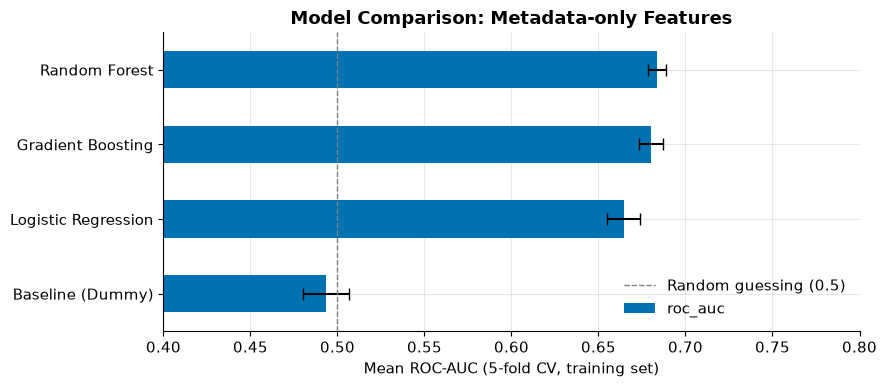

Best model by cross-validated ROC-AUC: Random Forest


In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
cv_results["roc_auc"].sort_values().plot(
    kind="barh", xerr=cv_results["roc_auc_std"].sort_values(), color=PRIMARY_COLOR, capsize=4, ax=ax
)
ax.axvline(0.5, color="grey", linestyle="--", linewidth=1, label="Random guessing (0.5)")
ax.set_xlim(0.4, 0.8)
ax.set_xlabel("Mean ROC-AUC (5-fold CV, training set)")
ax.set_ylabel("")
ax.set_title("Model Comparison: Metadata-only Features")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

best_model_name = cv_results.index[0]
print(f"Best model by cross-validated ROC-AUC: {best_model_name}")

## 5. Final Evaluation on the Held-Out Test Set

The best cross-validated model is refit on the full training set and evaluated **once** on the test set it has never seen.

In [7]:
best_pipeline = Pipeline([("preprocess", make_preprocessor()), ("model", models[best_model_name])])
best_pipeline.fit(X_train, y_train)

test_probabilities = best_pipeline.predict_proba(X_test)[:, 1]
test_predictions = best_pipeline.predict(X_test)

test_metrics = {
    "ROC-AUC": roc_auc_score(y_test, test_probabilities),
    "Balanced accuracy": balanced_accuracy_score(y_test, test_predictions),
    "Macro F1": f1_score(y_test, test_predictions, average="macro"),
}
for metric, value in test_metrics.items():
    print(f"{metric:<18}: {value:.4f}")

print()
print(classification_report(y_test, test_predictions, target_names=["Not Negative", "Negative"], digits=3))

ROC-AUC           : 0.6913
Balanced accuracy : 0.6357
Macro F1          : 0.6316

              precision    recall  f1-score   support

Not Negative      0.524     0.589     0.555      1080
    Negative      0.736     0.682     0.708      1817

    accuracy                          0.648      2897
   macro avg      0.630     0.636     0.632      2897
weighted avg      0.657     0.648     0.651      2897



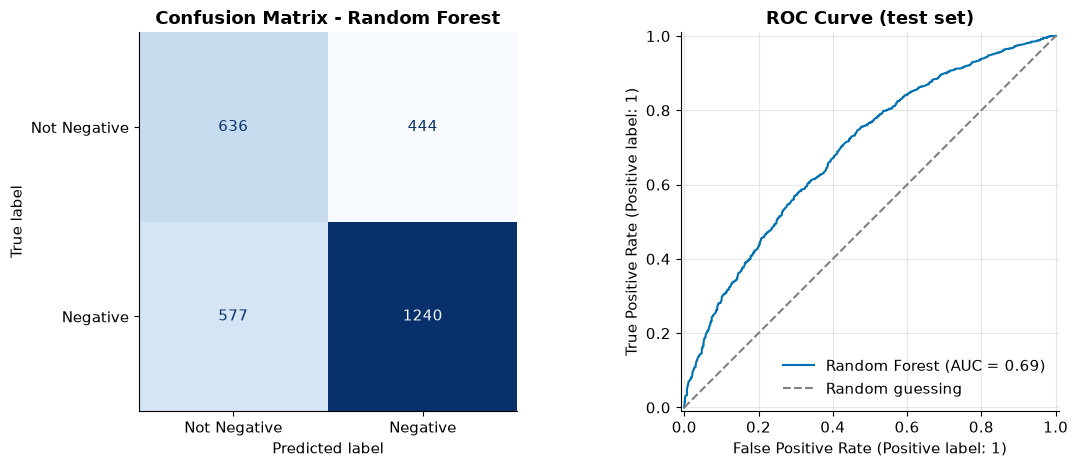

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

ConfusionMatrixDisplay.from_predictions(
    y_test, test_predictions, display_labels=["Not Negative", "Negative"],
    cmap="Blues", ax=axes[0], colorbar=False,
)
axes[0].set_title(f"Confusion Matrix - {best_model_name}")

RocCurveDisplay.from_predictions(y_test, test_probabilities, ax=axes[1], name=best_model_name)
axes[1].plot([0, 1], [0, 1], linestyle="--", color="grey", label="Random guessing")
axes[1].set_title("ROC Curve (test set)")
axes[1].legend(loc="lower right")

plt.tight_layout()
axes[0].grid(False)
plt.show()

## 6. Which Factors Matter? (Permutation Importance)

Permutation importance shuffles one original column at a time in the **test** set and measures how much ROC-AUC drops. A large drop means the model relies on that column. Because it works on the original columns, it is easier to explain to a business audience than one-hot coefficients.

,auc_drop_mean,auc_drop_std
feature,,
airline,0.1739,0.0070
hour,0.0156,0.0021
retweet_count,0.0120,0.0039
user_timezone,0.0118,0.0038
has_location,0.0077,0.0027
has_timezone,0.0019,0.0009


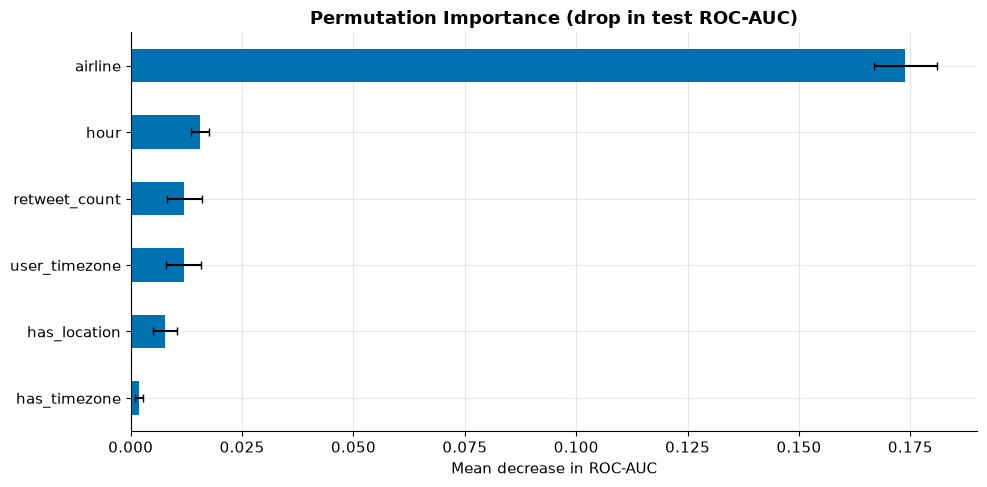

In [9]:
importance = permutation_importance(
    best_pipeline, X_test, y_test, scoring="roc_auc",
    n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1,
)

importance_table = pd.DataFrame({
    "feature": feature_columns,
    "auc_drop_mean": importance.importances_mean,
    "auc_drop_std": importance.importances_std,
}).sort_values("auc_drop_mean", ascending=False).set_index("feature")
display(importance_table.round(4))

ax = importance_table["auc_drop_mean"].sort_values().plot(
    kind="barh", xerr=importance_table["auc_drop_std"].sort_values(), color=PRIMARY_COLOR, capsize=3
)
ax.set_title("Permutation Importance (drop in test ROC-AUC)")
ax.set_xlabel("Mean decrease in ROC-AUC")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

## 7. How Much Does Airline Alone Explain?

If airline dominates the importance chart, a simple model using **only** airline should come close to the full model. This tells us how much the other metadata adds.

In [10]:
airline_only_pipeline = Pipeline([
    ("preprocess", ColumnTransformer([("categorical", OneHotEncoder(handle_unknown="ignore"), ["airline"])])),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)),
])
airline_only_pipeline.fit(X_train, y_train)
airline_only_auc = roc_auc_score(y_test, airline_only_pipeline.predict_proba(X_test)[:, 1])

print(f"Airline-only model test ROC-AUC: {airline_only_auc:.4f}")
print(f"Full metadata model test ROC-AUC: {test_metrics['ROC-AUC']:.4f}")
print(f"Improvement from the other metadata features: {test_metrics['ROC-AUC'] - airline_only_auc:+.4f}")

Airline-only model test ROC-AUC: 0.6621
Full metadata model test ROC-AUC: 0.6913
Improvement from the other metadata features: +0.0291


## 8. Business Use: Ranking Tweets by Complaint Risk

Even a moderate model can help prioritise. The test tweets are sorted by predicted probability of being Negative and split into five equal groups (quintiles). If the model is useful, the top group should contain a clearly higher share of real Negative tweets than the bottom group.

In [11]:
risk_table = pd.DataFrame({"predicted_probability": test_probabilities, "actual_negative": y_test.to_numpy()})
risk_table["risk_quintile"] = pd.qcut(
    risk_table["predicted_probability"].rank(method="first"), q=5,
    labels=["Q1 (lowest)", "Q2", "Q3", "Q4", "Q5 (highest)"],
)

quintile_summary = risk_table.groupby("risk_quintile", observed=True).agg(
    tweets=("actual_negative", "size"),
    actual_negative_pct=("actual_negative", lambda s: s.mean() * 100),
    avg_predicted_probability=("predicted_probability", "mean"),
).round(2)
quintile_summary

,tweets,actual_negative_pct,avg_predicted_probability
risk_quintile,,,
Q1 (lowest),580,38.10,0.30
Q2,579,54.75,0.41
Q3,579,66.15,0.53
Q4,579,71.16,0.61
Q5 (highest),580,83.45,0.71


## 9. Conclusions

The summary below is generated from the results above.

In [12]:
baseline_auc = cv_results.loc["Baseline (Dummy)", "roc_auc"]
top_feature = importance_table.index[0]

print(f"1. Best model: {best_model_name} - test ROC-AUC {test_metrics['ROC-AUC']:.3f}, "
      f"balanced accuracy {test_metrics['Balanced accuracy']:.3f}, macro F1 {test_metrics['Macro F1']:.3f}.")
print(f"2. That clearly beats the baseline (CV ROC-AUC {baseline_auc:.3f}), but is far from perfect.")
print(f"3. Most important factor: '{top_feature}'. An airline-only model reaches ROC-AUC {airline_only_auc:.3f}.")
print(f"4. Highest-risk quintile: {quintile_summary['actual_negative_pct'].iloc[-1]:.1f}% actually Negative "
      f"vs {quintile_summary['actual_negative_pct'].iloc[0]:.1f}% in the lowest quintile.")

1. Best model: Random Forest - test ROC-AUC 0.691, balanced accuracy 0.636, macro F1 0.632.
2. That clearly beats the baseline (CV ROC-AUC 0.493), but is far from perfect.
3. Most important factor: 'airline'. An airline-only model reaches ROC-AUC 0.662.
4. Highest-risk quintile: 83.5% actually Negative vs 38.1% in the lowest quintile.


**What this means for the business**

- Metadata alone carries a **real but limited** signal about whether a tweet is a complaint. The model beats random guessing but misclassifies many tweets.
- **Which airline is being discussed is the strongest non-text signal.** This matches the descriptive and statistical results: perception differs substantially by airline.
- Hour of day, retweets and profile features add only a small amount on top of airline.
- The model is useful for **prioritisation** (the risk quintiles separate complaint rates), not for making automatic decisions about individual tweets.

**Limitations**

- Only ~8 days of data. Patterns may not generalise to other periods.
- `retweet_count` is observed after posting, so in a live setting it would only be available once a tweet starts spreading.
- American Airlines is present almost only on 22–24 Feb, so `airline` and `hour` partly encode the collection schedule.
- The tweet text, the most informative signal, is intentionally excluded here. Section 10 shows how much it adds.

## 10. Text vs Metadata on the Same Test Tweets

Sections 1–9 used a split stratified on the Negative flag. For a like-for-like comparison, both approaches are now trained and scored on the **same 3-class split as notebooks 06–10**, using the same binary target (Negative vs not) and metric (ROC-AUC). The text model is the final model from notebook 10 (`src.modeling.build_final_model`).

,ROC-AUC (Negative vs not)
Metadata only (sections 1-9),0.6774
Tweet text (final NLP model),0.9285


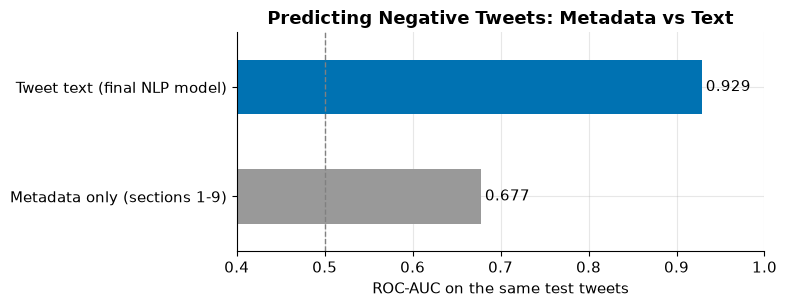

In [13]:
train_df, test_df = split_train_test(df)
final_model = build_final_model().fit(train_df["text"], train_df["airline_sentiment"])
binary_train = (train_df["airline_sentiment"] == "Negative").astype(int)
binary_test = (test_df["airline_sentiment"] == "Negative").astype(int)

# Text model: probability of the Negative class from the 3-class model
negative_index = list(final_model.classes_).index("Negative")
text_auc = roc_auc_score(binary_test, final_model.predict_proba(test_df["text"])[:, negative_index])

# Metadata model: same features and settings as sections 1-9, fitted on this split's training rows only
metadata_model = Pipeline([("preprocess", make_preprocessor()), ("model", models[best_model_name])])
metadata_model.fit(metadata_features(train_df), binary_train)
metadata_auc = roc_auc_score(binary_test, metadata_model.predict_proba(metadata_features(test_df))[:, 1])

comparison = pd.Series({"Metadata only (sections 1-9)": metadata_auc, "Tweet text (final NLP model)": text_auc})
display(comparison.round(4).to_frame("ROC-AUC (Negative vs not)"))

fig, ax = plt.subplots(figsize=(8, 3.2))
comparison.plot(kind="barh", color=[SENTIMENT_COLORS["Neutral"], PRIMARY_COLOR], ax=ax)
ax.axvline(0.5, color="grey", linestyle="--", linewidth=1)
ax.set_xlim(0.4, 1)
ax.set_xlabel("ROC-AUC on the same test tweets")
ax.set_title("Predicting Negative Tweets: Metadata vs Text")
ax.bar_label(ax.containers[0], fmt="%.3f", padding=3)
plt.tight_layout()
save_figure("text_vs_metadata.png")
plt.show()

**Interpretation:** the text carries far more signal than timing, retweets or profile fields. ROC-AUC rises from about 0.68 to about 0.93 on the same test tweets. This confirms the conclusion of sections 1–9: the metadata ceiling is low because *what customers say* is what determines sentiment.